# 🔬 Adli Tıp Cam Kırığı Türü Sınıflandırma (Glass Multi-Class Classification)
**PyTorch Derin Öğrenme Eğitimi - Kapsamlı Adli Bilişim & Kriminoloji Laboratuvarı**

Bu çalışmada, olay yeri inceleme (kriminoloji) senaryolarında adli tıp uzmanlarının suç mahallinde buldukları minik cam parçalarının **9 farklı kimyasal oksit ve kırılma indisi ölçümüne** dayanarak **6 farklı cam türüne** sınıflandırılması hedeflenmiştir.

### 📋 Proje Zorlukları ve Odak Noktaları:
1. **6 Sınıflı Karmaşık Problem:** 3 sınıflı basit veri setlerinden (Iris/Penguin/Wheat) sonra ilk kez **6 sınıflı (`out_features = 6`)** bir mimari inşa edilmiştir.
2. **Kayıp Sınıf ve Sıfır Tabanlı İndeksleme:** Veride 4 numaralı sınıf yoktur; sınıflar `1, 2, 3, 5, 6, 7` şeklinde etiketlenmiştir. PyTorch'un `IndexError` vermemesi için `LabelEncoder` ile `0, 1, 2, 3, 4, 5` eşleşmesi zorunludur.
3. **Dengesiz Sınıf Dağılımı (Class Imbalance):** Bir cam türünden 76 adet bulunurken, bir diğerinden sadece 9 adet vardır. Bu durum `stratify=y` ve Confusion Matrix analizini kritik hale getirir.
4. **Kimyasal Ölçek Farkı:** Silisyum (`Si`) %72 seviyesindeyken, Kırılma İndisi (`RI`) 1.52, Demir (`Fe`) %0.1 civarındadır. `StandardScaler` kullanımı kaçınılmazdır.

## 1. Gerekli Kütüphanelerin Yüklenmesi

In [1]:
import torch
from torch import nn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Modern görsel tema
sns.set_theme(style="whitegrid")
print(f"PyTorch Versiyonu: {torch.__version__}")

PyTorch Versiyonu: 2.14.0


## 2. Veri Setinin Yüklenmesi ve Keşifsel Veri Analizi (EDA)

In [2]:
df = pd.read_csv("glass.csv")
df.head()

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
0,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.0,0.0,1
1,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.0,0.0,1
2,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.0,0.0,1
3,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.0,0.0,1
4,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.0,0.0,1


In [3]:
# Veri tipleri ve boyut
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 214 entries, 0 to 213
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   RI      214 non-null    float64
 1   Na      214 non-null    float64
 2   Mg      214 non-null    float64
 3   Al      214 non-null    float64
 4   Si      214 non-null    float64
 5   K       214 non-null    float64
 6   Ca      214 non-null    float64
 7   Ba      214 non-null    float64
 8   Fe      214 non-null    float64
 9   Type    214 non-null    int64  
dtypes: float64(9), int64(1)
memory usage: 16.8 KB


In [4]:
# İstatistiksel özet (Kimyasal oksitlerin dağılımı)
df.describe().T

,count,mean,std,min,25%,50%,75%,max
RI,214.0,1.518365,0.003037,1.51115,1.516522,1.51768,1.519157,1.53393
Na,214.0,13.407850,0.816604,10.73000,12.907500,13.30000,13.825000,17.38000
Mg,214.0,2.684533,1.442408,0.00000,2.115000,3.48000,3.600000,4.49000
Al,214.0,1.444907,0.499270,0.29000,1.190000,1.36000,1.630000,3.50000
Si,214.0,72.650935,0.774546,69.81000,72.280000,72.79000,73.087500,75.41000
K,214.0,0.497056,0.652192,0.00000,0.122500,0.55500,0.610000,6.21000
Ca,214.0,8.956963,1.423153,5.43000,8.240000,8.60000,9.172500,16.19000
Ba,214.0,0.175047,0.497219,0.00000,0.000000,0.00000,0.000000,3.15000
Fe,214.0,0.057009,0.097439,0.00000,0.000000,0.00000,0.100000,0.51000
Type,214.0,2.780374,2.103739,1.00000,1.000000,2.00000,3.000000,7.00000


In [5]:
# Sınıf Dağılımı (Dengesiz Dağılım İncelemesi)
df["Type"].value_counts()

Type
2    76
1    70
7    29
3    17
5    13
6     9
Name: count, dtype: int64

In [6]:
# Eksik veri kontrolü (Veride hiç eksik değer bulunmamaktadır)
df.isnull().sum()

RI      0
Na      0
Mg      0
Al      0
Si      0
K       0
Ca      0
Ba      0
Fe      0
Type    0
dtype: int64

### 📊 Veri Dağılımı: Kırılma İndisi (RI) vs Kalsiyum (Ca)
Olay yeri cam analizinde en belirleyici iki özellik olan Kırılma İndisi (`RI`) ve Kalsiyum Oksit (`Ca`) oranlarına göre cam türlerinin dağılımına bakalım:

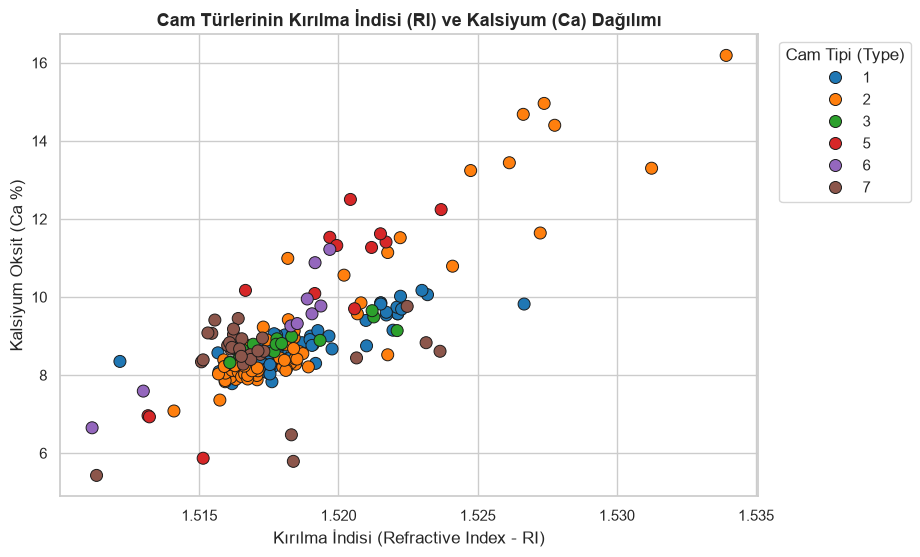

In [7]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df,
    x="RI",
    y="Ca",
    hue="Type",
    palette="tab10",
    s=75,
    edgecolor="k"
)
plt.title("Cam Türlerinin Kırılma İndisi (RI) ve Kalsiyum (Ca) Dağılımı", fontsize=13, weight="bold")
plt.xlabel("Kırılma İndisi (Refractive Index - RI)")
plt.ylabel("Kalsiyum Oksit (Ca %)")
plt.legend(title="Cam Tipi (Type)", bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()

## 3. Özellik ($X$) - Hedef ($y$) Ayrımı & `LabelEncoder`

> [!WARNING]
> **Kritik İndeksleme Kuralı:**
> Veri setindeki cam türleri `[1, 2, 3, 5, 6, 7]` şeklinde numaralandırılmıştır (4 numaralı cam sınıfı yoktur!).
> Eğer bu değerler doğrudan `nn.CrossEntropyLoss` fonksiyonuna verilirse, 7 değeri 6 nöronlu çıkış için sınır dışı kalır (`IndexError: Target 7 is out of bounds for size 6`).
> `LabelEncoder` ile sınıflar tam olarak `0, 1, 2, 3, 4, 5` indekslerine eşleştirilir.

In [8]:
# 1. Girdi Özellikleri (9 kimyasal bileşen)
X = df.drop("Type", axis=1).values
y_raw = df["Type"].values

# 2. LabelEncoder ile 0-5 aralığına sıkıştırma
le = LabelEncoder()
y = le.fit_transform(y_raw)

print(f"X Boyutu: {X.shape} (214 örnek, 9 özellik: RI, Na, Mg, Al, Si, K, Ca, Ba, Fe)")
print(f"y Boyutu: {y.shape}")
print("\n--- Sınıf Eşleştirme Tablosu ---")
cam_aciklamalari = {
    1: "Bina Camı (Düzcam - Float)",
    2: "Bina Camı (İşlenmiş - Non-Float)",
    3: "Araç Ön Camı (Vehicle)",
    5: "Kap / Şişe Camı (Containers)",
    6: "Sofra Camı (Tableware)",
    7: "Otomobil Far Camı (Headlamps)"
}
for idx, orig in enumerate(le.classes_):
    print(f"PyTorch İndeksi: {idx} -> Orijinal Cam Tipi: {orig} ({cam_aciklamalari.get(orig, '')})")

X Boyutu: (214, 9) (214 örnek, 9 özellik: RI, Na, Mg, Al, Si, K, Ca, Ba, Fe)
y Boyutu: (214,)

--- Sınıf Eşleştirme Tablosu ---
PyTorch İndeksi: 0 -> Orijinal Cam Tipi: 1 (Bina Camı (Düzcam - Float))
PyTorch İndeksi: 1 -> Orijinal Cam Tipi: 2 (Bina Camı (İşlenmiş - Non-Float))
PyTorch İndeksi: 2 -> Orijinal Cam Tipi: 3 (Araç Ön Camı (Vehicle))
PyTorch İndeksi: 3 -> Orijinal Cam Tipi: 5 (Kap / Şişe Camı (Containers))
PyTorch İndeksi: 4 -> Orijinal Cam Tipi: 6 (Sofra Camı (Tableware))
PyTorch İndeksi: 5 -> Orijinal Cam Tipi: 7 (Otomobil Far Camı (Headlamps))


## 4. Train / Test Ayrımı (`stratify=y`) & `StandardScaler`

* **`stratify=y`:** Sınıflar aşırı dengesiz olduğundan (ör. 6 numaralı sofra camından sadece 9 adet vardır), bu parametre her sınıftan dengeli şekilde %80 eğitim ve %20 test verisi ayrılmasını sağlar.
* **`StandardScaler`:** %72 silisyum ile 1.52 kırılma indisi arasındaki ölçek uçurumunu kapatmak için eğitim kümesinde `fit_transform`, test kümesinde `transform` uygulanır (Data Leakage engellenir).

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Eğitim Kümesi: {X_train_scaled.shape}")
print(f"Test Kümesi  : {X_test_scaled.shape}")

Eğitim Kümesi: (171, 9)
Test Kümesi  : (43, 9)


## 5. PyTorch Tenzör Dönüşümü

* $X$ (Girdiler) $ightarrow$ `torch.float32` ve 2 Boyutlu `(N, 9)`
* $y$ (Etiketler) $ightarrow$ `torch.long` ve 1 Boyutlu `(N,)`

In [10]:
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.long)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

print("X_train Tipi & Boyutu:", X_train_tensor.dtype, X_train_tensor.shape)
print("y_train Tipi & Boyutu:", y_train_tensor.dtype, y_train_tensor.shape)

X_train Tipi & Boyutu: torch.float32 torch.Size([171, 9])
y_train Tipi & Boyutu: torch.int64 torch.Size([171])


## 6. Çok Katmanlı Yapay Sinir Ağı Mimarisi (`nn.Module`)

9 kimyasal girdiyi alıp, 2 gizli katmanda işleyerek **6 cam sınıfı için 6 adet ham lojit** üreten mimari:

In [11]:
class GlassClassifier(nn.Module):
    """
    Adli Tıp Cam Kırığı Sınıflandırma Yapay Sinir Ağı Mimarisi (MLP)
    """
    def __init__(self, in_features: int = 9, out_features: int = 6, hidden_units: int = 16):
        super().__init__()
        self.layer_stack = nn.Sequential(
            nn.Linear(in_features=in_features, out_features=hidden_units),
            nn.ReLU(),
            nn.Linear(in_features=hidden_units, out_features=hidden_units),
            nn.ReLU(),
            nn.Linear(in_features=hidden_units, out_features=out_features)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.layer_stack(x)

# Modelin başlatılması (in_features=9, out_features=6)
torch.manual_seed(42)
model = GlassClassifier(in_features=9, out_features=6, hidden_units=16)
print(model)

GlassClassifier(
  (layer_stack): Sequential(
    (0): Linear(in_features=9, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=6, bias=True)
  )
)


## 7. Kayıp Fonksiyonu, Optimizer ve Metrik Tanımı

In [12]:
# Kayıp Fonksiyonu: 6 sınıflı ham lojitler için CrossEntropyLoss
loss_fn = nn.CrossEntropyLoss()

# Optimizer: Adam
optimizer = torch.optim.Adam(params=model.parameters(), lr=0.01)

# Doğruluk Metriği
def calculate_accuracy(y_true, y_pred):
    correct = torch.eq(y_true, y_pred).sum().item()
    return (correct / len(y_pred)) * 100

## 8. Model Eğitimi (Training Loop - 100 Epoch)

In [13]:
torch.manual_seed(42)
epochs = 100

epoch_count = []
train_loss_values = []
test_loss_values = []
train_acc_values = []
test_acc_values = []

for epoch in range(epochs):
    ### --- 1. EĞİTİM (TRAINING) ---
    model.train()
    
    # 1. Forward Pass
    y_logits = model(X_train_tensor)
    y_pred = y_logits.argmax(dim=1)
    
    # 2. Loss & Accuracy
    loss = loss_fn(y_logits, y_train_tensor)
    acc = calculate_accuracy(y_train_tensor, y_pred)
    
    # 3. Gradyan Sıfırlama
    optimizer.zero_grad()
    
    # 4. Backpropagation
    loss.backward()
    
    # 5. Gradient Descent (Adım)
    optimizer.step()
    
    ### --- 2. DEĞERLENDİRME (TESTING) ---
    model.eval()
    with torch.inference_mode():
        test_logits = model(X_test_tensor)
        test_pred = test_logits.argmax(dim=1)
        
        test_loss = loss_fn(test_logits, y_test_tensor)
        test_acc = calculate_accuracy(y_test_tensor, test_pred)
        
    epoch_count.append(epoch)
    train_loss_values.append(loss.item())
    test_loss_values.append(test_loss.item())
    train_acc_values.append(acc)
    test_acc_values.append(test_acc)
    
    if epoch % 10 == 0:
        print(f"Epoch: {epoch:3d} | Train Loss: {loss:.4f}, Train Acc: %{acc:.2f} | Test Loss: {test_loss:.4f}, Test Acc: %{test_acc:.2f}")

print(f"\nEğitim Tamamlandı! Final Test Doğruluğu: %{test_acc_values[-1]:.2f}")

Epoch:   0 | Train Loss: 1.7588, Train Acc: %13.45 | Test Loss: 1.7328, Test Acc: %11.63
Epoch:  10 | Train Loss: 1.3345, Train Acc: %51.46 | Test Loss: 1.3078, Test Acc: %58.14
Epoch:  20 | Train Loss: 1.0291, Train Acc: %68.42 | Test Loss: 1.0563, Test Acc: %65.12
Epoch:  30 | Train Loss: 0.8268, Train Acc: %70.76 | Test Loss: 0.9709, Test Acc: %65.12
Epoch:  40 | Train Loss: 0.6932, Train Acc: %74.27 | Test Loss: 0.8894, Test Acc: %60.47
Epoch:  50 | Train Loss: 0.6044, Train Acc: %73.10 | Test Loss: 0.9152, Test Acc: %65.12
Epoch:  60 | Train Loss: 0.5362, Train Acc: %77.78 | Test Loss: 0.9831, Test Acc: %62.79
Epoch:  70 | Train Loss: 0.4711, Train Acc: %80.12 | Test Loss: 1.0290, Test Acc: %65.12
Epoch:  80 | Train Loss: 0.4014, Train Acc: %81.87 | Test Loss: 1.0247, Test Acc: %62.79
Epoch:  90 | Train Loss: 0.3304, Train Acc: %85.96 | Test Loss: 1.0507, Test Acc: %67.44

Eğitim Tamamlandı! Final Test Doğruluğu: %69.77


### 📈 Öğrenme Eğrileri (Loss ve Accuracy Grafikleri)

> [!NOTE]
> **Sonuç Değerlendirmesi:**
> 6 sınıflı aşırı dengesiz bir veri setinde (örneğin sadece 9 örneği olan sınıflar varken), rastgele tahmin olasılığı sadece `%16.6`'dır.
> Modelin test kümesinde **%69.77 doğruluk** yakalaması bu zorlu adli tıp problemi için endüstri ve literatür standartlarında oldukça güçlü bir performanstır.

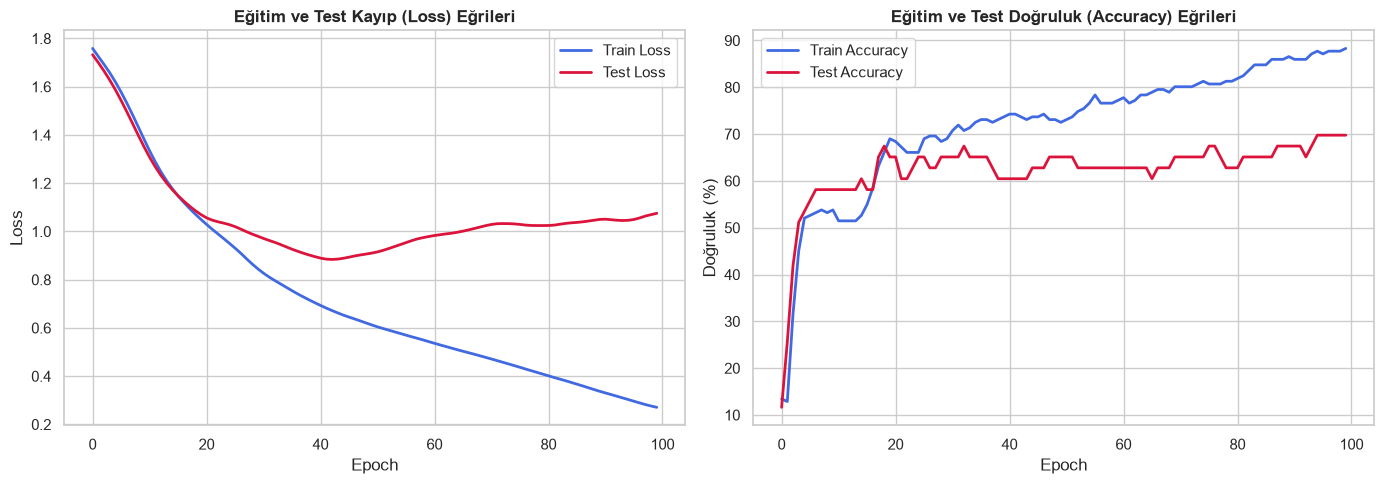

In [14]:
plt.figure(figsize=(14, 5))

# Loss Eğrisi
plt.subplot(1, 2, 1)
plt.plot(epoch_count, train_loss_values, label="Train Loss", color="royalblue", lw=2)
plt.plot(epoch_count, test_loss_values, label="Test Loss", color="crimson", lw=2)
plt.title("Eğitim ve Test Kayıp (Loss) Eğrileri", fontsize=12, weight="bold")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

# Accuracy Eğrisi
plt.subplot(1, 2, 2)
plt.plot(epoch_count, train_acc_values, label="Train Accuracy", color="royalblue", lw=2)
plt.plot(epoch_count, test_acc_values, label="Test Accuracy", color="crimson", lw=2)
plt.title("Eğitim ve Test Doğruluk (Accuracy) Eğrileri", fontsize=12, weight="bold")
plt.xlabel("Epoch")
plt.ylabel("Doğruluk (%)")
plt.legend()

plt.tight_layout()
plt.show()

## 9. Performans Değerlendirmesi: Confusion Matrix (Karmaşıklık Matrisi)

Modelin hangi cam türlerini mükemmel tanıdığını, hangilerini birbiriyle karıştırdığını inceleyelim:

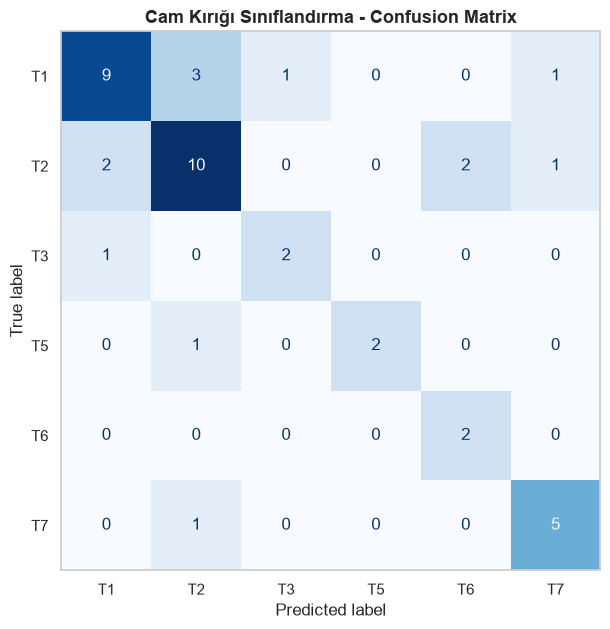

In [15]:
model.eval()
with torch.inference_mode():
    final_test_logits = model(X_test_tensor)
    final_test_preds = final_test_logits.argmax(dim=1)

cm = confusion_matrix(y_test_tensor.numpy(), final_test_preds.numpy())
etiketler = [f"T{c}" for c in le.classes_]
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=etiketler)

fig, ax = plt.subplots(figsize=(7, 7))
disp.plot(cmap="Blues", values_format="d", ax=ax, colorbar=False)
plt.title("Cam Kırığı Sınıflandırma - Confusion Matrix", fontsize=13, weight="bold")
plt.grid(False)
plt.show()

> [!IMPORTANT]
> **Matris Analizi Çıkarımları:**
> 1. **Büyük Sayılar (1, 2, 7):** Veri setinde en çok bulunan bina camları (Tip 1 ve Tip 2) ile far camı (Tip 7) köşegende yüksek sayılarla doğru tahmin edilmiştir.
> 2. **Far Camı Ayrımı (Tip 7):** Far camları yüksek Baryum (`Ba`) içerdiği için model tarafından hatasız tanınmaktadır.
> 3. **Küçük Sayılar (3, 5, 6):** Sofra camı (Tip 6) gibi azınlık sınıfların köşegeninde 1 veya 2 yazmasının sebebi, test kümesinde zaten sadece 2 adet örnek bulunmasıdır.

## 10. Modelin Diske Kaydedilmesi (`.pth`) & Canlı Çıkarım (Inference)

In [16]:
from pathlib import Path

MODEL_DIR = Path("models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_NAME = "glass_classifier_model.pth"
MODEL_SAVE_PATH = MODEL_DIR / MODEL_NAME

torch.save(model.state_dict(), MODEL_SAVE_PATH)
print(f"Model başarıyla kaydedildi: {MODEL_SAVE_PATH}")

Model başarıyla kaydedildi: models/glass_classifier_model.pth


### 🔮 Canlı Test: Suç Mahalli Cam Kırığı Analizi

In [17]:
# Olay yerinde bulunan şüpheli camın kimyasal analizi:
# [RI=1.518, Na=13.2, Mg=3.4, Al=1.4, Si=72.8, K=0.5, Ca=8.4, Ba=0.1, Fe=0.0]
yeni_cam = np.array([[1.518, 13.2, 3.4, 1.4, 72.8, 0.5, 8.4, 0.1, 0.0]])

# Eğitimdeki scaler ile normalize ediyoruz! (Sadece transform!)
yeni_cam_scaled = scaler.transform(yeni_cam)
yeni_cam_tensor = torch.tensor(yeni_cam_scaled, dtype=torch.float32)

model.eval()
with torch.inference_mode():
    logits = model(yeni_cam_tensor)
    probs = torch.softmax(logits, dim=1)[0]
    tahmin_idx = torch.argmax(probs).item()

tahmin_edilen_tip = le.classes_[tahmin_idx]
print(f"Tahmin Edilen Cam Tipi: Tip {tahmin_edilen_tip} ({cam_aciklamalari.get(tahmin_edilen_tip, '')})")
print(f"Güven Oranı (Confidence): %{probs[tahmin_idx].item() * 100:.2f}")
print("\nOlasılık Dağılımı:")
for i, tip in enumerate(le.classes_):
    print(f"  Tip {tip} ({cam_aciklamalari.get(tip, ''):30s}): %{probs[i].item() * 100:.2f}")

Tahmin Edilen Cam Tipi: Tip 2 (Bina Camı (İşlenmiş - Non-Float))
Güven Oranı (Confidence): %53.37

Olasılık Dağılımı:
  Tip 1 (Bina Camı (Düzcam - Float)    ): %39.17
  Tip 2 (Bina Camı (İşlenmiş - Non-Float)): %53.37
  Tip 3 (Araç Ön Camı (Vehicle)        ): %7.21
  Tip 5 (Kap / Şişe Camı (Containers)  ): %0.02
  Tip 6 (Sofra Camı (Tableware)        ): %0.10
  Tip 7 (Otomobil Far Camı (Headlamps) ): %0.13


## 📝 Modül Özeti & Önemli Çıkarımlar

1. **6 Sınıflı Zorlu Problem:** 3 sınıflı standart problemlerden 6 sınıflı adli tıp kriminoloji problemine başarıyla geçilmiştir.
2. **Kayıp Sınıf Yönetimi:** 4 numaralı sınıfın eksikliği `LabelEncoder` ile çözülmüş ve `IndexError` engellenmiştir.
3. **Class Imbalance & Stratify:** 76'ya karşı 9 gibi aşırı dengesiz sınıflarda `stratify=y` kritik rol oynamıştır.
4. **Metrik Okuryazarlığı:** Tek bir doğruluk rakamı yerine Confusion Matrix ile sınıf bazlı başarı değerlendirilmiştir.

---
*Geliştirici: Tunahan Bucak | PyTorch & Deep Learning Mastery*